# WEEK 10 Practice - Working with BST

In this week practice, you can use the Python implementation from lectures to complete the tasks given below.

In [3]:
from graphviz import Digraph
from IPython.display import SVG
from collections import deque


'''
graphviz and ipython.display are used to visualize the generated tree.

This code defines a Node data structure with attributes value, left and right. Value is the integer value stored in node. 
Attribute left is a pointer to the left child of a node, once initialized it's None.
Attribute right is a pointer to the right child, correspondingly.

The Binary Search Tree (BST) data structure is a tree consisting of nodes. The left sub-tree consists of all values less than 
the value of the node, the right sub-tree of all values greater than the current node value.

The BST data structure has functions:
* add a node
* delete a node
* search a node
* preorder traversal (DF traversal)
* inorder traversal (DF traversal)
* postorder traversal (DF traversal)
* print for all traverlsal types
* visualise for graphical print
'''

class Node:
    def __init__(self,value):
        self.value = value
        self.left = None
        self.right = None
        
class BST:
    def __init__(self):
        self.root = None
        
    def _add(self, current, value):
        
        if self.root == None:
            self.root = Node(value)
        else:
            if value < current.value:
                if current.left == None:
                    current.left = Node(value)
                else:
                    self._add(current.left, value)
            else:
                if current.right == None:
                    current.right = Node(value)
                else:
                    self._add(current.right, value)
      
    def add(self, value):
        new_node = Node(value)
        
        if self.root == None:
            self.root = new_node
            
        else:
             self._add(self.root, value)
    
    def delete(self,root, key):
        """
        Delete a node with the given key from a binary search tree.

        :param root: The root of the binary search tree.
        :param key: The value of the node to be deleted.
        :return: The new root of the binary search tree.
        """
        if not root:
            return None

        if key < root.value:
            root.left = self.delete(root.left, key)
        elif key > root.value:
            root.right = self.delete(root.right, key)
        else:
            if not root.left:
                return root.right
            elif not root.right:
                return root.left
            else:
                temp = self.find_min(root.right)
                root.value = temp.value
                root.right = self.delete(root.right, temp.value)

        return root

    def find_min(self,root):
        while root.left:
            root = root.left
        return root
        
    # returns a node whose value == input value
    # if no node with input value is found, None is returned
    def _search(self, node, value):
        if node is None or node.value == value:
            return node          
        
        if value < node.value:
            return self._search(node.left, value)
        else:
            return self._search(node.right,value) 
        
    # prints the result of search: does a node with input value exist in the BST or not                   
    def search(self, value):
        result = self._search(self.root,value)
        
        if result is None:
            print(f"NO node with value {value} found in BST!")
        elif result.value == value:
            print(f"YES, a node with value {value} found in BST!")
    
    
    # visiting = print the value of the node
    def visit(self, node):
        print(node.value)
    
    # There are different types of in-depth traversals: pre-order, in-order and post-order
    # Here's an algorithm for all those
    
    # pre-order traversal
    def preorder(self, current):
        if current is not None:
            self.visit(current)
            self.preorder(current.left)
            self.preorder(current.right)
        
    def preprint(self):
        self.preorder(self.root)

    # inorder traversal
    def inorder(self, current):
        if current is not None:
            self.inorder(current.left)
            self.visit(current)
            self.inorder(current.right)
    
    def inprint(self):
        self.inorder(self.root)

    #postorder traversal
    def postorder(self, current):
        if current is not None:
            self.postorder(current.left)
            self.postorder(current.right)
            self.visit(current)
            
    def postprint(self):
        self.postorder(self.root)
    
    def level_order_traversal(self,root):
        """
        Perform level-order traversal on a binary tree.

        :param root: The root of the binary tree.
        :return: A list containing the values in the binary tree in level-order traversal order.
        """
        if not root:
            return []

        res = []
        q = deque([root])

        while q:
            level_size = len(q)
            level_vals = []
            for _ in range(level_size):
                node = q.popleft()
                level_vals.append(node.value)
                if node.left:
                    q.append(node.left)
                if node.right:
                    q.append(node.right)
            res.append(level_vals)

        return res

    def levelprint(self):
        levellist = self.level_order_traversal(self.root)
        for item in levellist:
            print(item)
                
    # visualize the BST with graphviz digraph
    def visualize(self):
        dot = Digraph(comment='Binary Tree')
        
        def add_nodes_edges(node):
            if node is None:
                return
            dot.node(str(node.value), str(node.value))
            if node.left is not None:
                dot.edge(str(node.value), str(node.left.value))
                add_nodes_edges(node.left)
            if node.right is not None:
                dot.edge(str(node.value), str(node.right.value))
                add_nodes_edges(node.right)
        
        add_nodes_edges(self.root)
        return SVG(dot.pipe(format='svg'))


# Driver code here!

# Task 1 - Create a BST object and add values to BST

In this task, you should first generate an instance of a new BST.

Then add elements **7, 10, 3, 6, 12, 15, 2, 5, 11** to the BST in this order.

Use the *visualize* algorithm to show the generated BST.

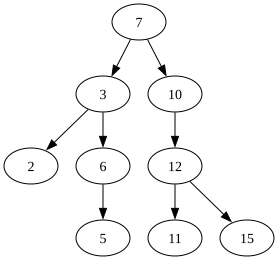

In [4]:
# 1. creat a BST object (instance) from BST class:
bst = BST()

# 2. add values to BST:
elements = [7, 10, 3, 6, 12, 15, 2, 5, 11]

# Add elements to BST tree
for val in elements:
    bst.add(val)

# 3. Visulalise BST with visualize()
bst.visualize()

# Task 2 - Search items in BST

In this task, you should search for this items in your BST:
* 6 (positive result)
* 5 (positive result)
* 13 (negative result)
* 4 (negative result)

You should also search for the minimum and maximum value in the tree using the tree search / traversal algorithms. In other words, write an algorithm that returns the minimum value of the tree, and another algorithm for finding the maximum value.

In [5]:
# ==========================================
# 1. Searching as requred:
# ==========================================
print("--- SEARCH RESULT ---")
bst.search(6)
bst.search(5)
bst.search(13)
bst.search(4)

# ==========================================
# 2. Find Min and Max
# ==========================================
def find_minimum(root):
    # the min is at the at the bottom left of the tree
    if root is None:
        return None
    current = root
    while current.left is not None:
        current = current.left
    return current.value

def find_maximum(root):
    # the max is at the at the bottom right of the tree
    if root is None:
        return None
    current = root
    while current.right is not None:
        current = current.right
    return current.value

# ==========================================
# 3. Check Min and Max
# ==========================================
min_val = find_minimum(bst.root)
max_val = find_maximum(bst.root)

print("\n--- MAX AND MIN ---")
print(f"Minimum in the BST: {min_val}")
print(f"Maximum in the BST: {max_val}")

--- SEARCH RESULT ---
YES, a node with value 6 found in BST!
YES, a node with value 5 found in BST!
NO node with value 13 found in BST!
NO node with value 4 found in BST!

--- MAX AND MIN ---
Minimum in the BST: 2
Maximum in the BST: 15


# Task 3 - Depth and height algorithm

An algorithm telling the height or the depth of a node are still missing from the BST implementation.

Write an algorithm for those and demonstrate the use of those algorithms for the root, a leaf and some internal node in your BST.

In [6]:
# ==========================================
# 1. Algorithm to find the Depth of a node
# ==========================================
def get_depth(root, target_val):
    """
    Find the depth through target_val from root.
    Return number of edges
    if not found return -1.
    """
    depth = 0
    current = root
    
    while current is not None:
        if current.value == target_val:
            return depth
        elif target_val < current.value:
            current = current.left
            depth += 1
        else:
            current = current.right
            depth += 1
            
    return -1  # not found

# ==========================================
# 2. Find (Height) of a Node
# ==========================================
def _calculate_height(node):
    """find height from a  Node """
    if node is None:
        return -1
    left_height = _calculate_height(node.left)
    right_height = _calculate_height(node.right)
    return 1 + max(left_height, right_height)

def get_height(root, target_val):
    """
    Find the node with  target_val and calculate the height.
    if not found return -1.
    """
    # FInd node:
    current = root
    while current is not None:
        if current.value == target_val:
            break
        elif target_val < current.value:
            current = current.left
        else:
            current = current.right
            
    if current is None:
        return -1  # Node not found
        
    return _calculate_height(current)

# ==========================================
# 3. Demonstration
# ==========================================
test_nodes = {
    "Root node (Root)": 7,
    "Internal nodes": 10,
    "Leaf nodes": 5
}

print(f"{'Node types':<35} | {'Values':<8} | {'Depth':<8} | {'Height':<8}")
print("-" * 65)

for node_type, val in test_nodes.items():
    depth = get_depth(bst.root, val)
    height = get_height(bst.root, val)
    print(f"{node_type:<35} | {val:<8} | {depth:<8} | {height:<8}")

Node types                          | Values   | Depth    | Height  
-----------------------------------------------------------------
Root node (Root)                    | 7        | 0        | 3       
Internal nodes                      | 10       | 1        | 2       
Leaf nodes                          | 5        | 3        | 0       


# Task 4 - Deleting nodes from the BST

Choose three nodes from your tree such that:
* one of the nodes is a leaf
* one of the nodes has only one child
* one of the nodes has two children

Delete those nodes and after each deletion, visualise the new BST with the visualize() algorithm.
Describe, with your own words, how the deletion algorithm works in these three different cases.

--- 1. DELETE NODE (2) ---


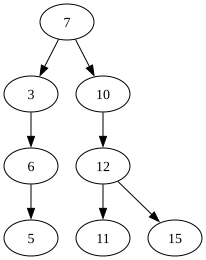

--- 2. DELETE NODE (6) ---


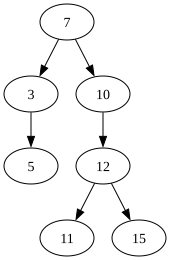

--- 3. DELETE NODE WITH 2 CHILDREN NODE (12) ---


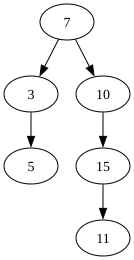

In [7]:
# ==========================================================
# CASE 1: DELETE Leaf node 2
# ==========================================================
print("--- 1. DELETE NODE (2) ---")
bst.root = bst.delete(bst.root, 2)
display(bst.visualize())

# ==========================================================
# CASE 2: NODE WITH 1 CHILDE - NODE 6
# ==========================================================
print("--- 2. DELETE NODE (6) ---")
bst.root = bst.delete(bst.root, 6)
display(bst.visualize())

# ==========================================================
# CASE 3: DELETE NODE WITH 2 CHILDREN - NODE 12
# ==========================================================
print("--- 3. DELETE NODE WITH 2 CHILDREN NODE (12) ---")
bst.root = bst.delete(bst.root, 12)
display(bst.visualize())

### EXPLANATION:
- Case 1: Delete Node is a leaf — ví dụ nút 2:

Method: The algorithm searches from root to NOde 2. If left and right are None, return Node to parent Node 3. --> Pointer of node 3 becomes None. Node 2 is deleted without affecting other nodes of the tree. 

- Case 2: Node has only one child — Node(6)   

Method: Algorithm checks Node 6 and finds only left node (5), right node is None. Algorithm returns child node (root.left, node 5) to connect to NOde 5 to parent Node 3. Now, Node 3 points to Node 5 instead of Node 6.

- Case 3: Delete Node which has two children — Node (12)   

Method: Since node 12 has 2 children (11 & 15), we can not delete directly. Algorithm checks inorder successor — min node on the right (find_min(root.right)).

# Task 5 Predecessor and successor

**Predecessor of a node** is the node visited just before this node in inorder traversal.

**Successor of a node** is the node visited just after this node in inorder traversal.

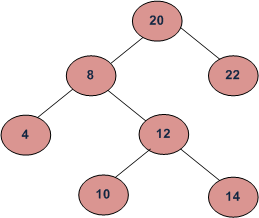

For example, in the above graph, the inorder successor of 8 is 10, whereas the predecessor is 4.

The inorder successor of 14 is 20, whereas the inorder predecessor is 12.

Write an algorithm for finding the predecessor and an algorithm for finding the successor of a given node.

In [12]:
# ==========================================================
# 1. Find Inorder Predecessor
# ==========================================================
def find_predecessor(root, target_val):

    predecessor = None
    current = root

    while current:
        if current.value == target_val:
            if current.left:
                temp = current.left
                while temp.right:
                    temp = temp.right
                predecessor = temp
            break
        elif target_val > current.value:
            predecessor = current
            current = current.right
        else:
            current = current.left

    return predecessor.value if predecessor else None


# ==========================================================
# 2. Find Inorder Successor
# ==========================================================
def find_successor(root, target_val):
    successor = None
    current = root

    while current:
        if current.value == target_val:
            if current.right:
                temp = current.right
                while temp.left:
                    temp = temp.left
                successor = temp
            break
        elif target_val < current.value:
            successor = current
            current = current.left
        else:
            current = current.right

    return successor.value if successor else None

# example:
demo_tree = BST()
for x in [20, 8, 22, 4, 12, 10, 14]:
    demo_tree.add(x)

print("--- EXAMPLE ---")
for val in [8, 14]:
    pred = find_predecessor(demo_tree.root, val)
    succ = find_successor(demo_tree.root, val)
    print(f"NODE {val:<2} -> Predecessor: {pred}, Successor: {succ}")

print("\n--- TEST ON  BST ---")
print("Inorder traversal:")
bst.inprint()

test_values = [3, 7, 10, 11]
for val in test_values:
    pred = find_predecessor(bst.root, val)
    succ = find_successor(bst.root, val)
    print(f"NODE {val:<2} -> Predecessor: {pred}, Successor: {succ}")

--- EXAMPLE ---
NODE 8  -> Predecessor: 4, Successor: 10
NODE 14 -> Predecessor: 12, Successor: 20

--- TEST ON  BST ---
Inorder traversal:
3
5
7
10
11
15
NODE 3  -> Predecessor: None, Successor: 5
NODE 7  -> Predecessor: 5, Successor: 10
NODE 10 -> Predecessor: 7, Successor: 11
NODE 11 -> Predecessor: 10, Successor: 15
